# Lightweight Deep Learning for TB Screening: Benchmark Pipeline

**Goal:** train 7 architectures on TBX11K, test internally and on two external datasets (Shenzhen, Montgomery),
measure efficiency (params, GFLOPs, size, CPU latency), and audit Grad-CAM attention.

**Before running (Kaggle):**
1. Settings → Accelerator → **GPU T4 x2 / P100**; Settings → **Internet ON** (needed to download pretrained weights).
2. *Add Data* → add the TBX11K, Shenzhen and Montgomery datasets, then edit the three paths in Section 1.
3. Run once with `QUICK = True` (about 5 minutes) to make sure everything works. Then set `QUICK = False` for the real run.

**Outputs** are written to `results/` (metrics, predictions, figures). The run is resumable: finished (model, seed) pairs are skipped.

## 1. Configuration

In [1]:
import os, re, io, sys, json, time, copy, random, platform, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.utils.flop_counter import FlopCounterMode
import torchvision
from torchvision import transforms as T
import timm
from PIL import Image
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
warnings.filterwarnings("ignore")

# ---------------- EDIT THESE ----------------
SZ_ROOT  = "/kaggle/input/datasets/kmader/pulmonary-chest-xray-abnormalities"
MC_ROOT  = "/kaggle/input/datasets/kmader/pulmonary-chest-xray-abnormalities"
TBX_ROOT = "/kaggle/input/datasets/vbookshelf/tbx11k-simplified"   # fill in after Step 1
# --------------------------------------------

QUICK      = False      # True = tiny smoke test, False = full experiment
PRETRAINED = True      # ImageNet weights (needs Internet ON)
IMG_CACHE  = 256       # images are cached at this size, then resized to IMG_SIZE
IMG_SIZE   = 224
BATCH      = 32
EPOCHS     = 2 if QUICK else 15
PATIENCE   = 4
SEEDS      = [0] if QUICK else [0, 1, 2]
LR, WD     = 3e-4, 1e-4
N_BOOT     = 200 if QUICK else 1000
NEAR_DUP_BITS = 10     # near-duplicate threshold (bits of 256) for the leakage check
NUM_WORKERS = 2

# name -> (library, architecture)
MODELS = {
    "MobileNetV3-L":      ("timm", "mobilenetv3_large_100"),
    "EfficientNet-B0":    ("timm", "efficientnet_b0"),
    "EfficientNet-Lite0": ("timm", "efficientnet_lite0"),
    "MobileViT-S":        ("timm", "mobilevit_s"),
    "ShuffleNetV2":       ("tv",   "shufflenet_v2_x1_0"),
    "SqueezeNet1.1":      ("tv",   "squeezenet1_1"),
    "ResNet50 (ref.)":    ("timm", "resnet50"),
}
if QUICK:
    MODELS = {k: MODELS[k] for k in ["MobileNetV3-L", "ShuffleNetV2"]}

BASE = Path("/kaggle/working") if Path("/kaggle").exists() else Path(".")
OUT = BASE / "results"
for d in ["", "preds", "ckpt", "figs"]:
    (OUT / d).mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
print("device:", DEVICE, "| torch", torch.__version__, "| timm", timm.__version__)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

device: cuda | torch 2.11.0+cu128 | timm 1.0.29


## 2. Build the data manifest
Labels come from the file names: Shenzhen/Montgomery end in `_0` (normal) or `_1` (TB); TBX11K files starting with `tb` are TB,
`h` (healthy) and `s` (sick, non-TB) are negatives. **Check the printed counts against the dataset documentation.**

In [2]:
IMG_EXT = {".png", ".jpg", ".jpeg", ".bmp"}
def list_images(root):
    out = []
    for p in Path(root).rglob("*"):
        if p.suffix.lower() not in IMG_EXT:
            continue
        parts = [x.lower() for x in p.parts]
        if p.name.startswith(".") or "__macosx" in parts or any("mask" in x for x in parts):
            continue   # skip macOS junk and segmentation masks
        out.append(p)
    return sorted(out)
def build_nlm(root, pattern, name):
    rows = []
    for p in list_images(root):
        m = re.match(pattern, p.stem)
        if m:
            rows.append((str(p), int(m.group(1)), name))
    return pd.DataFrame(rows, columns=["path", "y", "source"])

def build_tbx(root):
    rows = []
    for p in list_images(root):
        parts = [x.lower() for x in p.parts]
        if "test" in parts:          # unlabeled challenge test images
            continue
        s = p.stem.lower()
        if s.startswith("tb"):       y = 1
        elif s.startswith("h"):      y = 0   # healthy
        elif s.startswith("s"):      y = 0   # sick but non-TB
        else:                        continue
        rows.append((str(p), y, "tbx11k"))
    return pd.DataFrame(rows, columns=["path", "y", "source"])

df_tbx = build_tbx(TBX_ROOT)
df_sz  = build_nlm(SZ_ROOT, r"CHNCXR_\d+_([01])", "shenzhen")
df_mc  = build_nlm(MC_ROOT, r"MCUCXR_\d+_([01])", "montgomery")
for n, d in [("TBX11K", df_tbx), ("Shenzhen", df_sz), ("Montgomery", df_mc)]:
    print(f"{n:11s} n={len(d):6d}  TB={int(d.y.sum()):5d}  non-TB={int((1-d.y).sum()):5d}")
assert len(df_tbx) > 0 and len(df_sz) > 0 and len(df_mc) > 0, "A dataset path is wrong or no labeled images were found."

TBX11K      n=  8400  TB=  800  non-TB= 7600
Shenzhen    n=   662  TB=  336  non-TB=  326
Montgomery  n=   138  TB=   58  non-TB=   80


## 3. Cache images (grayscale, resized) and check for cross-dataset leakage
A 16x16 average hash flags near-identical images between TBX11K and the external sets. Any TBX11K image that matches an
external image is removed from TBX11K, so the external test sets stay truly unseen.

In [3]:
df_all = pd.concat([df_tbx, df_sz, df_mc], ignore_index=True)
df_all["i"] = np.arange(len(df_all))

def load_gray(path):
    im = Image.open(path).convert("L").resize((IMG_CACHE, IMG_CACHE), Image.BILINEAR)
    return np.asarray(im, dtype=np.uint8)

t0 = time.time()
with ThreadPoolExecutor(4) as ex:
    IMGS = np.stack(list(ex.map(load_gray, df_all.path)))
print(f"cached {IMGS.shape} in {time.time()-t0:.0f}s ({IMGS.nbytes/1e6:.0f} MB)")

def ahash(arr, k=16):
    a = np.asarray(Image.fromarray(arr).resize((k, k), Image.BILINEAR), dtype=np.float32)
    return (a > a.mean()).ravel()

H = np.stack([ahash(a) for a in IMGS])
is_tbx = (df_all.source == "tbx11k").values
H_tbx, H_ext = H[is_tbx], H[~is_tbx]
min_d = np.full(len(H_tbx), 999)
for s in range(0, len(H_tbx), 500):
    d = (H_tbx[s:s+500, None, :] != H_ext[None, :, :]).sum(-1)
    min_d[s:s+500] = d.min(1)
dup = min_d <= NEAR_DUP_BITS
print("min Hamming distance to any external image: "
      f"min={min_d.min()}  p1={np.percentile(min_d,1):.0f}  median={np.median(min_d):.0f}")
print(f"TBX11K images flagged as near-duplicates of external sets (<= {NEAR_DUP_BITS} bits): {dup.sum()}")
df_tbx_clean = df_all[is_tbx].reset_index(drop=True)
df_tbx_clean = df_tbx_clean[~dup].reset_index(drop=True)

cached (9200, 256, 256) in 405s (603 MB)
min Hamming distance to any external image: min=5  p1=12  median=26
TBX11K images flagged as near-duplicates of external sets (<= 10 bits): 22


## 4. Splits
TBX11K is split 70/15/15 (train / val / internal test), stratified by label. Shenzhen and Montgomery are never used for training
or threshold selection. *Limitation to state in the paper:* TBX11K has no patient IDs, so patient-level splitting is not possible.

In [4]:
def split_tbx(df, seed=42):
    tr, tmp = train_test_split(df, test_size=0.30, stratify=df.y, random_state=seed)
    va, te  = train_test_split(tmp, test_size=0.50, stratify=tmp.y, random_state=seed)
    return tr.reset_index(drop=True), va.reset_index(drop=True), te.reset_index(drop=True)

df_tr, df_va, df_te = split_tbx(df_tbx_clean)
df_sz_i = df_all[df_all.source == "shenzhen"].reset_index(drop=True)
df_mc_i = df_all[df_all.source == "montgomery"].reset_index(drop=True)
if QUICK:
    df_tr = df_tr.sample(min(len(df_tr), 400), random_state=0).reset_index(drop=True)
    df_va = df_va.sample(min(len(df_va), 150), random_state=0).reset_index(drop=True)
    df_te = df_te.sample(min(len(df_te), 150), random_state=0).reset_index(drop=True)
TEST_SETS = {"TBX11K-test": df_te, "Shenzhen": df_sz_i, "Montgomery": df_mc_i}
for n, d in [("train", df_tr), ("val", df_va)] + list(TEST_SETS.items()):
    print(f"{n:12s} n={len(d):5d}  TB={int(d.y.sum()):5d} ({100*d.y.mean():.0f}%)")

train        n= 5864  TB=  559 (10%)
val          n= 1257  TB=  120 (10%)
TBX11K-test  n= 1257  TB=  119 (9%)
Shenzhen     n=  662  TB=  336 (51%)
Montgomery   n=  138  TB=   58 (42%)


## 5. Dataset, transforms, models

In [5]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
tf_train = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)),
                      T.RandomAffine(degrees=8, translate=(0.05, 0.05), scale=(0.95, 1.05)),
                      T.ColorJitter(brightness=0.15, contrast=0.15),
                      T.ToTensor(), T.Normalize(MEAN, STD)])
tf_eval  = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor(), T.Normalize(MEAN, STD)])

class CXR(Dataset):
    def __init__(self, df, tf): self.i, self.y, self.tf = df.i.values, df.y.values.astype(np.float32), tf
    def __len__(self): return len(self.i)
    def __getitem__(self, k):
        img = Image.fromarray(IMGS[self.i[k]]).convert("RGB")
        return self.tf(img), self.y[k]

class TVNet(nn.Module):
    """Wraps a torchvision backbone so every model exposes forward_features / forward_head (needed for Grad-CAM)."""
    def __init__(self, features, dim, drop=0.2):
        super().__init__()
        self.features = features
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(drop), nn.Linear(dim, 1))
    def forward_features(self, x): return self.features(x)
    def forward_head(self, f):     return self.head(f)
    def forward(self, x):          return self.forward_head(self.forward_features(x))

def build_model(name, pretrained=True):
    lib, arch = MODELS[name]
    if lib == "timm":
        return timm.create_model(arch, pretrained=pretrained, num_classes=1)
    if arch == "shufflenet_v2_x1_0":
        w = torchvision.models.ShuffleNet_V2_X1_0_Weights.IMAGENET1K_V1 if pretrained else None
        b = torchvision.models.shufflenet_v2_x1_0(weights=w)
        return TVNet(nn.Sequential(b.conv1, b.maxpool, b.stage2, b.stage3, b.stage4, b.conv5), 1024)
    if arch == "squeezenet1_1":
        w = torchvision.models.SqueezeNet1_1_Weights.IMAGENET1K_V1 if pretrained else None
        b = torchvision.models.squeezenet1_1(weights=w)
        return TVNet(b.features, 512)
    raise ValueError(name)

def fwd(model, x):
    return model(x).squeeze(-1)

## 6. Training and prediction

In [6]:
@torch.no_grad()
def predict(model, df, bs=64):
    model.eval()
    dl = DataLoader(CXR(df, tf_eval), batch_size=bs, shuffle=False, num_workers=NUM_WORKERS)
    out = []
    for x, _ in dl:
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            lo = fwd(model, x.to(DEVICE, non_blocking=True))
        out.append(torch.sigmoid(lo.float()).cpu().numpy())
    return np.concatenate(out)

def train_one(name, seed):
    set_seed(seed)
    model = build_model(name, PRETRAINED).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
    pos_w = torch.tensor((1 - df_tr.y.mean()) / df_tr.y.mean(), device=DEVICE)
    crit = nn.BCEWithLogitsLoss(pos_weight=pos_w)
    g = torch.Generator(); g.manual_seed(seed)
    dl = DataLoader(CXR(df_tr, tf_train), batch_size=BATCH, shuffle=True, drop_last=True,
                    num_workers=NUM_WORKERS, pin_memory=True, generator=g)
    best_auc, best_state, bad = -1, None, 0
    for ep in range(EPOCHS):
        model.train(); tl, n, t0 = 0.0, 0, time.time()
        for x, y in dl:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                loss = crit(fwd(model, x).float(), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item() * len(y); n += len(y)
        sched.step()
        va_auc = roc_auc_score(df_va.y, predict(model, df_va))
        print(f"  [{name} s{seed}] ep{ep+1:02d} loss={tl/n:.4f} val_auc={va_auc:.4f} ({time.time()-t0:.0f}s)")
        if va_auc > best_auc:
            best_auc, bad = va_auc, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE: break
    model.load_state_dict(best_state)
    return model, best_auc

## 7. Metrics with bootstrap confidence intervals
The decision threshold is chosen **once** on the TBX11K validation set (Youden's J) and then applied unchanged to every test set.
This mimics real deployment and exposes calibration shift. AUC is threshold-free and shows ranking ability.

In [7]:
def youden_threshold(y, p):
    fpr, tpr, thr = roc_curve(y, p)
    return float(thr[np.argmax(tpr - fpr)])

def point_metrics(y, p, thr):
    pred = p >= thr
    tp = int(((pred == 1) & (y == 1)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
    fp = int(((pred == 1) & (y == 0)).sum()); fn = int(((pred == 0) & (y == 1)).sum())
    sens = tp / max(tp + fn, 1); spec = tn / max(tn + fp, 1)
    prec = tp / max(tp + fp, 1)
    f1 = 2 * prec * sens / max(prec + sens, 1e-12)
    return dict(auc=roc_auc_score(y, p), sens=sens, spec=spec, f1=f1, acc=(tp + tn) / len(y))

def bootstrap_ci(y, p, thr, n=N_BOOT, seed=0):
    rng = np.random.default_rng(seed)
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    stats = []
    for _ in range(n):
        idx = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
        stats.append(point_metrics(y[idx], p[idx], thr))
    st = pd.DataFrame(stats)
    return {f"{k}_lo": st[k].quantile(0.025) for k in st} | {f"{k}_hi": st[k].quantile(0.975) for k in st}

## 8. Run all experiments (resumable)

In [8]:
METRICS_CSV = OUT / "metrics_per_run.csv"
done = pd.read_csv(METRICS_CSV) if METRICS_CSV.exists() else pd.DataFrame()
done_keys = set(zip(done.model, done.seed)) if len(done) else set()
rows = done.to_dict("records") if len(done) else []

for name in MODELS:
    for seed in SEEDS:
        if (name, seed) in done_keys:
            print(f"skip {name} seed {seed} (already done)"); continue
        print(f"\n=== {name} | seed {seed} ===")
        model, best_val = train_one(name, seed)
        p_val = predict(model, df_va)
        thr = youden_threshold(df_va.y.values, p_val)
        preds = {"val": p_val}
        for tname, tdf in TEST_SETS.items():
            preds[tname] = predict(model, tdf)
        pooled_y = np.concatenate([df_sz_i.y.values, df_mc_i.y.values])
        pooled_p = np.concatenate([preds["Shenzhen"], preds["Montgomery"]])
        evals = {k: (TEST_SETS[k].y.values, preds[k]) for k in TEST_SETS}
        evals["SZ+MC pooled"] = (pooled_y, pooled_p)
        for tname, (y, p) in evals.items():
            r = dict(model=name, seed=seed, test_set=tname, thr=thr, val_auc=best_val, n=len(y))
            r.update(point_metrics(y, p, thr)); r.update(bootstrap_ci(y, p, thr))
            rows.append(r)
            print(f"  {tname:13s} AUC={r['auc']:.3f} [{r['auc_lo']:.3f},{r['auc_hi']:.3f}] sens={r['sens']:.3f} spec={r['spec']:.3f}")
        np.savez_compressed(OUT / "preds" / f"{name.replace(' ','_')}_s{seed}.npz", thr=thr, **{k.replace(' ', '_'): v for k, v in preds.items()})
        if seed == SEEDS[0]:
            torch.save(model.state_dict(), OUT / "ckpt" / f"{name.replace(' ','_')}_s{seed}.pt")
        pd.DataFrame(rows).to_csv(METRICS_CSV, index=False)
        del model; torch.cuda.empty_cache()

res = pd.DataFrame(rows)
print("\nsaved", METRICS_CSV)


=== MobileNetV3-L | seed 0 ===


model.safetensors: reconstructing file:   0%|          |  0.00B / 22.1MB            

model.safetensors: downloading bytes:           |  0.00B            

  [MobileNetV3-L s0] ep01 loss=1.6006 val_auc=0.9928 (33s)
  [MobileNetV3-L s0] ep02 loss=0.4851 val_auc=0.9852 (15s)
  [MobileNetV3-L s0] ep03 loss=0.3460 val_auc=0.9939 (15s)
  [MobileNetV3-L s0] ep04 loss=0.1379 val_auc=0.9974 (15s)
  [MobileNetV3-L s0] ep05 loss=0.0579 val_auc=0.9975 (15s)
  [MobileNetV3-L s0] ep06 loss=0.0939 val_auc=0.9968 (15s)
  [MobileNetV3-L s0] ep07 loss=0.0542 val_auc=0.9972 (15s)
  [MobileNetV3-L s0] ep08 loss=0.0770 val_auc=0.9973 (15s)
  [MobileNetV3-L s0] ep09 loss=0.0217 val_auc=0.9985 (15s)
  [MobileNetV3-L s0] ep10 loss=0.0205 val_auc=0.9985 (15s)
  [MobileNetV3-L s0] ep11 loss=0.0172 val_auc=0.9990 (15s)
  [MobileNetV3-L s0] ep12 loss=0.0236 val_auc=0.9992 (15s)
  [MobileNetV3-L s0] ep13 loss=0.0122 val_auc=0.9991 (15s)
  [MobileNetV3-L s0] ep14 loss=0.0083 val_auc=0.9989 (15s)
  [MobileNetV3-L s0] ep15 loss=0.0058 val_auc=0.9991 (15s)
  TBX11K-test   AUC=0.999 [0.998,1.000] sens=0.983 spec=0.979
  Shenzhen      AUC=0.586 [0.543,0.629] sens=0.973 sp

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

... (10 outputs left out)

  [SqueezeNet1.1 s0] ep01 loss=1.1846 val_auc=0.8731 (14s)
  [SqueezeNet1.1 s0] ep02 loss=0.8942 val_auc=0.9542 (14s)
  [SqueezeNet1.1 s0] ep03 loss=0.7699 val_auc=0.9748 (14s)
  [SqueezeNet1.1 s0] ep04 loss=0.6380 val_auc=0.9826 (14s)
  [SqueezeNet1.1 s0] ep05 loss=0.5478 val_auc=0.9867 (14s)
  [SqueezeNet1.1 s0] ep06 loss=0.4855 val_auc=0.9893 (14s)
  [SqueezeNet1.1 s0] ep07 loss=0.4201 val_auc=0.9899 (14s)
  [SqueezeNet1.1 s0] ep08 loss=0.4067 val_auc=0.9920 (14s)
  [SqueezeNet1.1 s0] ep09 loss=0.3215 val_auc=0.9936 (14s)
  [SqueezeNet1.1 s0] ep10 loss=0.2814 val_auc=0.9935 (14s)
  [SqueezeNet1.1 s0] ep11 loss=0.2490 val_auc=0.9946 (14s)
  [SqueezeNet1.1 s0] ep12 loss=0.2067 val_auc=0.9949 (14s)
  [SqueezeNet1.1 s0] ep13 loss=0.1857 val_auc=0.9946 (14s)
  [SqueezeNet1.1 s0] ep14 loss=0.1631 val_auc=0.9947 (14s)
  [SqueezeNet1.1 s0] ep15 loss=0.1408 val_auc=0.9948 (14s)
  TBX11K-test   AUC=0.994 [0.990,0.997] sens=0.950 spec=0.960
  Shenzhen      AUC=0.797 [0.760,0.830] sens=0.798 sp

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

  [ResNet50 (ref.) s0] ep01 loss=0.7874 val_auc=0.9703 (30s)
  [ResNet50 (ref.) s0] ep02 loss=0.3433 val_auc=0.9958 (31s)
  [ResNet50 (ref.) s0] ep03 loss=0.2297 val_auc=0.9900 (28s)
  [ResNet50 (ref.) s0] ep04 loss=0.1760 val_auc=0.9976 (30s)
  [ResNet50 (ref.) s0] ep05 loss=0.1335 val_auc=0.9979 (29s)
  [ResNet50 (ref.) s0] ep06 loss=0.1292 val_auc=0.9969 (28s)
  [ResNet50 (ref.) s0] ep07 loss=0.0922 val_auc=0.9914 (30s)
  [ResNet50 (ref.) s0] ep08 loss=0.0821 val_auc=0.9973 (29s)
  [ResNet50 (ref.) s0] ep09 loss=0.0488 val_auc=0.9968 (29s)
  TBX11K-test   AUC=0.995 [0.989,0.998] sens=0.966 spec=0.947
  Shenzhen      AUC=0.639 [0.600,0.685] sens=0.994 spec=0.046
  Montgomery    AUC=0.620 [0.532,0.713] sens=0.586 spec=0.625
  SZ+MC pooled  AUC=0.630 [0.591,0.668] sens=0.934 spec=0.160

=== ResNet50 (ref.) | seed 1 ===
  [ResNet50 (ref.) s1] ep01 loss=0.7875 val_auc=0.9824 (30s)
  [ResNet50 (ref.) s1] ep02 loss=0.3192 val_auc=0.9946 (29s)
  [ResNet50 (ref.) s1] ep03 loss=0.2640 val_auc

## 9. Efficiency benchmark (params, GFLOPs, size, CPU latency)
FLOPs are counted with PyTorch's `FlopCounterMode` (convolution and matmul operations; 1 multiply-add = 2 FLOPs).
Latency: batch size 1, median and 95th percentile over 100 runs after warm-up, on the CPU of this machine.
Report the CPU model in the paper and, ideally, repeat on the real target hardware (e.g. a Raspberry Pi or a low-end laptop).

In [9]:
def cpu_name():
    try:
        for l in open("/proc/cpuinfo"):
            if l.startswith("model name"): return l.split(":")[1].strip()
    except Exception: pass
    return platform.processor() or "unknown"

def model_stats(name):
    m = build_model(name, pretrained=False).eval()
    params = sum(p.numel() for p in m.parameters())
    buf = io.BytesIO(); torch.save(m.state_dict(), buf); size_mb = buf.tell() / 1e6
    x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
    with FlopCounterMode(display=False) as fc, torch.no_grad():
        m(x)
    gflops = fc.get_total_flops() / 1e9
    lat = {}
    for th in (1, 4):
        torch.set_num_threads(th)
        with torch.inference_mode():
            for _ in range(10): m(x)
            ts = []
            for _ in range(100):
                t0 = time.perf_counter(); m(x); ts.append((time.perf_counter() - t0) * 1000)
        lat[f"lat_ms_{th}t_median"] = float(np.median(ts)); lat[f"lat_ms_{th}t_p95"] = float(np.percentile(ts, 95))
    return dict(model=name, params_M=params / 1e6, size_MB=size_mb, GFLOPs=gflops, **lat)

eff = pd.DataFrame([model_stats(n) for n in MODELS])
eff["cpu"] = cpu_name()
eff.to_csv(OUT / "efficiency.csv", index=False)
print(eff.round(2).to_string(index=False))

             model  params_M  size_MB  GFLOPs  lat_ms_1t_median  lat_ms_1t_p95  lat_ms_4t_median  lat_ms_4t_p95                            cpu
     MobileNetV3-L      4.20    17.01    0.43             22.86          24.29             25.10          26.87 Intel(R) Xeon(R) CPU @ 2.00GHz
   EfficientNet-B0      4.01    16.32    0.77             36.55          39.80             31.94          34.57 Intel(R) Xeon(R) CPU @ 2.00GHz
EfficientNet-Lite0      3.37    13.76    0.77             29.89          31.22             26.94          31.47 Intel(R) Xeon(R) CPU @ 2.00GHz
       MobileViT-S      4.94    19.92    2.83             77.85          80.44             55.39          59.97 Intel(R) Xeon(R) CPU @ 2.00GHz
      ShuffleNetV2      1.25     5.19    0.29             19.41          20.50             22.76          30.67 Intel(R) Xeon(R) CPU @ 2.00GHz
     SqueezeNet1.1      0.72     2.91    0.53             26.50          27.72             16.42          17.28 Intel(R) Xeon(R) CPU @ 2.00GHz

## 10. Summary tables (mean ± SD over seeds) and figures

                    params_M  GFLOPs  size_MB  lat_ms_1t_median  lat_ms_4t_median AUC_drop (internal - pooled external) AUC TBX11K-test   AUC Shenzhen AUC Montgomery AUC SZ+MC pooled
model                                                                                                                                                                                 
MobileNetV3-L           4.20    0.43    17.01             22.86             25.10                         0.408 ± 0.114   0.999 ± 0.000  0.589 ± 0.133  0.574 ± 0.050    0.591 ± 0.114
EfficientNet-B0         4.01    0.77    16.32             36.55             31.94                         0.339 ± 0.080   0.998 ± 0.001  0.674 ± 0.102  0.596 ± 0.020    0.660 ± 0.080
EfficientNet-Lite0      3.37    0.77    13.76             29.89             26.94                         0.420 ± 0.058   0.999 ± 0.000  0.558 ± 0.078  0.598 ± 0.020    0.578 ± 0.058
MobileViT-S             4.94    2.83    19.92             77.85             55.39    

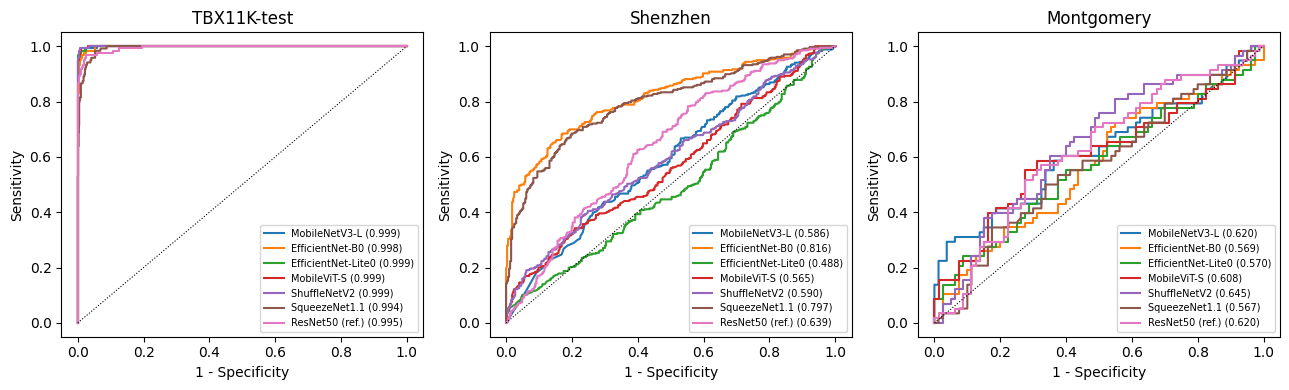

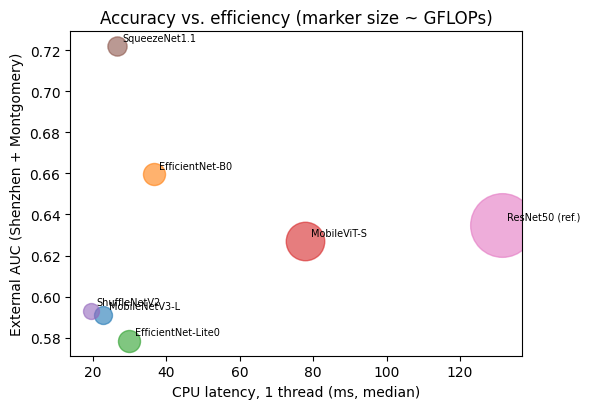

In [10]:
def fmt(s): return f"{s.mean():.3f} ± {s.std(ddof=0):.3f}" if len(s) > 1 else f"{s.mean():.3f}"
sets = ["TBX11K-test", "Shenzhen", "Montgomery", "SZ+MC pooled"]
tab = (res.groupby(["model", "test_set"])[["auc", "sens", "spec", "f1"]].agg(fmt).reset_index())
tab.to_csv(OUT / "summary_by_set.csv", index=False)
auc_wide = res.pivot_table(index=["model", "seed"], columns="test_set", values="auc").reset_index()
auc_wide["AUC_drop (internal - pooled external)"] = auc_wide["TBX11K-test"] - auc_wide["SZ+MC pooled"]
drop = auc_wide.groupby("model")["AUC_drop (internal - pooled external)"].agg(fmt)
final = eff.set_index("model")[["params_M", "GFLOPs", "size_MB", "lat_ms_1t_median", "lat_ms_4t_median"]].join(drop)
for s in sets:
    final[f"AUC {s}"] = res[res.test_set == s].groupby("model")["auc"].agg(fmt)
final.round(2).to_csv(OUT / "summary_final.csv")
print(final.round(2).to_string())

# ROC curves (first seed)
s0 = SEEDS[0]
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, tname in zip(axes, ["TBX11K-test", "Shenzhen", "Montgomery"]):
    for name in MODELS:
        f = np.load(OUT / "preds" / f"{name.replace(' ','_')}_s{s0}.npz")
        y, p = TEST_SETS[tname].y.values, f[tname]
        fpr, tpr, _ = roc_curve(y, p)
        ax.plot(fpr, tpr, label=f"{name} ({roc_auc_score(y, p):.3f})")
    ax.plot([0, 1], [0, 1], "k:", lw=0.8); ax.set_title(tname); ax.set_xlabel("1 - Specificity"); ax.set_ylabel("Sensitivity")
    ax.legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.savefig(OUT / "figs" / "roc_curves.png", dpi=300); plt.show()

# accuracy vs. efficiency trade-off
fig, ax = plt.subplots(figsize=(6, 4.2))
for name in MODELS:
    x = eff.set_index("model").loc[name, "lat_ms_1t_median"]
    y = res[(res.model == name) & (res.test_set == "SZ+MC pooled")]["auc"].mean()
    g = eff.set_index("model").loc[name, "GFLOPs"]
    ax.scatter(x, y, s=60 + 250 * g, alpha=0.6); ax.annotate(name, (x, y), fontsize=7, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("CPU latency, 1 thread (ms, median)"); ax.set_ylabel("External AUC (Shenzhen + Montgomery)")
ax.set_title("Accuracy vs. efficiency (marker size ~ GFLOPs)")
plt.tight_layout(); plt.savefig(OUT / "figs" / "tradeoff.png", dpi=300); plt.show()

## 11. Grad-CAM audit
Grad-CAM is computed on the last feature map. As a simple, reproducible shortcut check we report the **border attention ratio**:
the share of Grad-CAM mass in the outer 8% frame of the image (where text markers and hospital tokens often sit), divided by the
frame's share of the image area. A value near 1 means no special border preference; values well above 1 suggest the model uses the border.
*Later refinement:* with lung masks (Montgomery provides them) we can compute the fraction of attention inside the lungs.

             model    test_set  n_tb  border_ratio_mean  border_ratio_sd
     MobileNetV3-L TBX11K-test   119              0.526            0.268
     MobileNetV3-L    Shenzhen   336              0.532            0.230
     MobileNetV3-L  Montgomery    58              1.083            0.367
   EfficientNet-B0 TBX11K-test   119              0.747            0.282
   EfficientNet-B0    Shenzhen   336              0.500            0.162
   EfficientNet-B0  Montgomery    58              1.043            0.325
EfficientNet-Lite0 TBX11K-test   119              0.327            0.132
EfficientNet-Lite0    Shenzhen   336              0.208            0.090
EfficientNet-Lite0  Montgomery    58              0.774            0.371
       MobileViT-S TBX11K-test   119              1.457            0.317
       MobileViT-S    Shenzhen   336              1.036            0.187
       MobileViT-S  Montgomery    58              1.460            0.627
      ShuffleNetV2 TBX11K-test   119              0

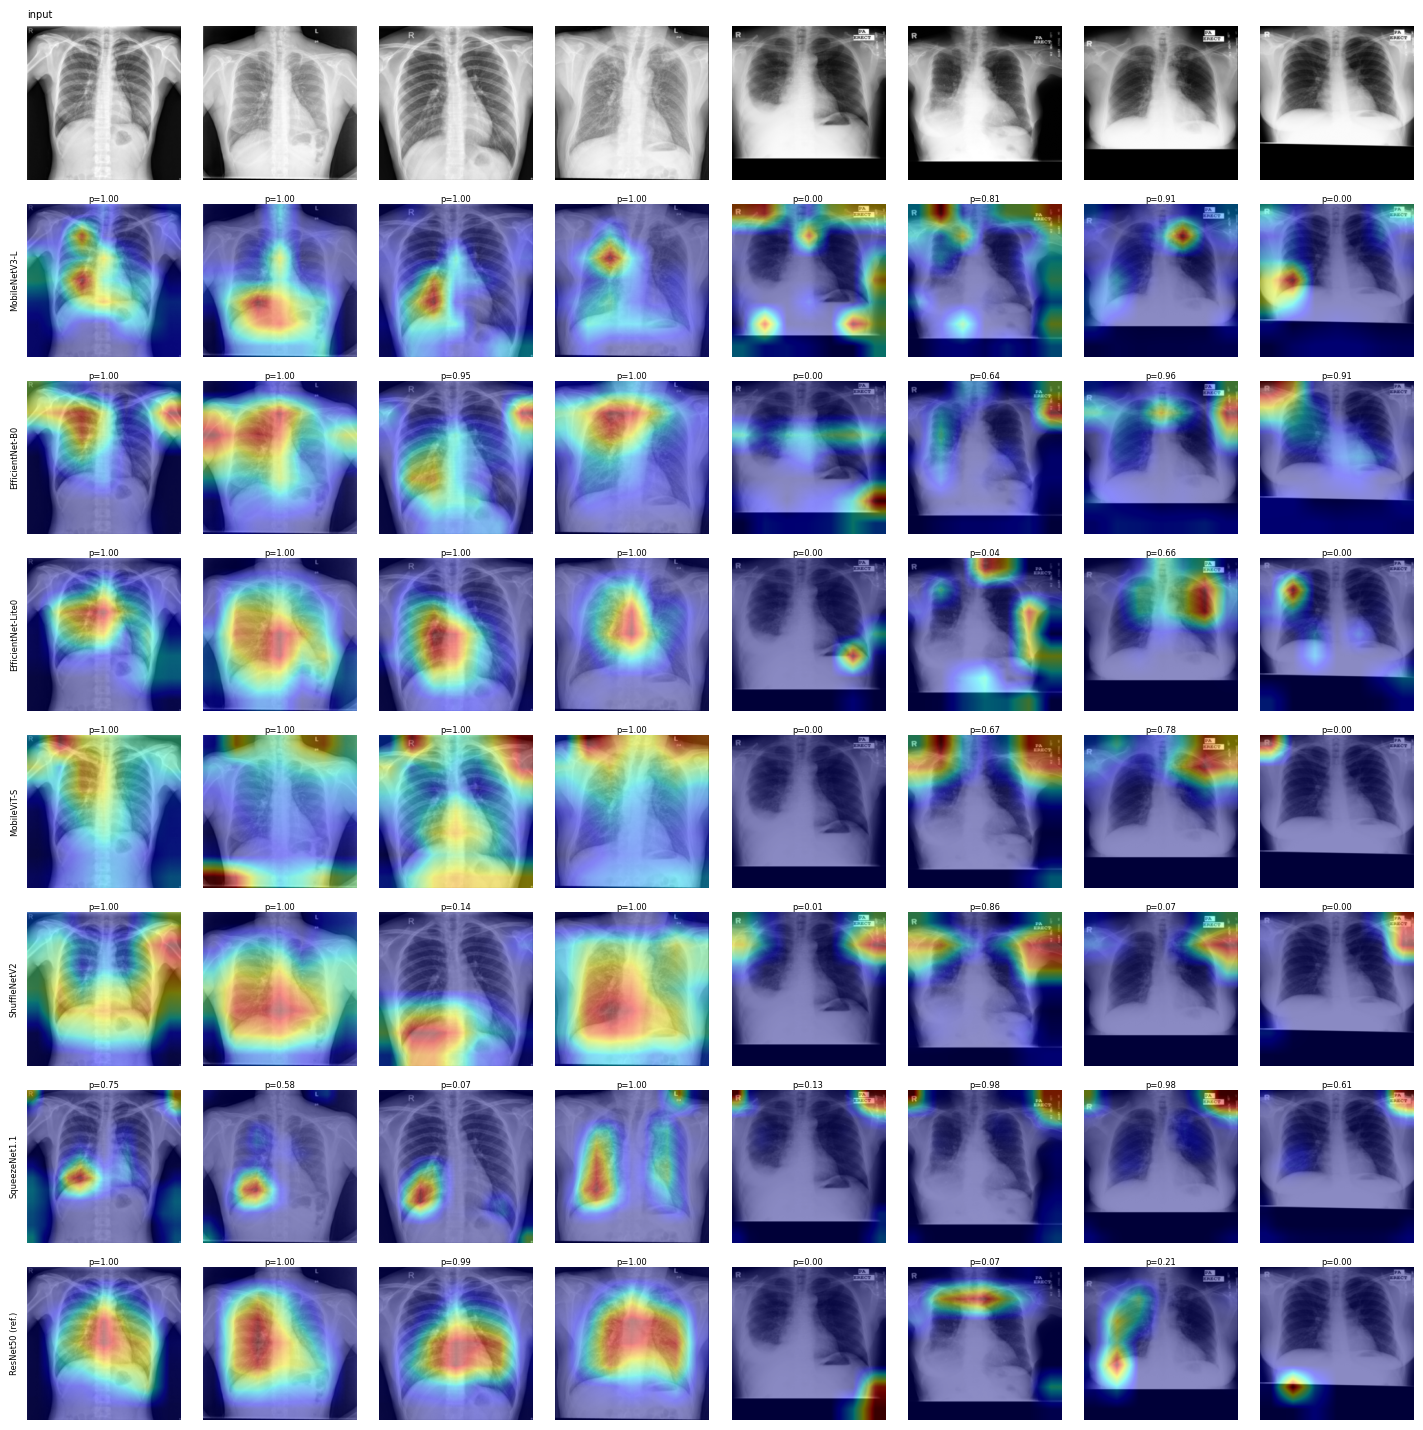

In [11]:
def gradcam(model, x):
    model.eval(); model.zero_grad()
    feats = model.forward_features(x); feats.retain_grad()
    logit = model.forward_head(feats).squeeze(-1)
    logit.sum().backward()
    w = feats.grad.mean((2, 3), keepdim=True)
    cam = F.relu((w * feats).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
    mn, mx = cam.amin((1, 2), keepdim=True), cam.amax((1, 2), keepdim=True)
    cam = (cam - mn) / (mx - mn + 1e-8)
    return cam.detach().cpu().numpy(), torch.sigmoid(logit).detach().cpu().numpy()

FRAME = 0.08
m = int(IMG_SIZE * FRAME)
ring = np.ones((IMG_SIZE, IMG_SIZE), bool); ring[m:-m, m:-m] = False
ring_area = ring.mean()

def load_ckpt(name):
    mdl = build_model(name, pretrained=False)
    mdl.load_state_dict(torch.load(OUT / "ckpt" / f"{name.replace(' ','_')}_s{SEEDS[0]}.pt", map_location="cpu"))
    return mdl.to(DEVICE)

def cams_for(model, df, bs=32):
    cams, probs = [], []
    for s in range(0, len(df), bs):
        xb = torch.stack([tf_eval(Image.fromarray(IMGS[i]).convert("RGB")) for i in df.i.values[s:s+bs]]).to(DEVICE)
        c, p = gradcam(model, xb); cams.append(c); probs.append(p)
    return np.concatenate(cams), np.concatenate(probs)

audit_rows = []
tb_sets = {"TBX11K-test": df_te[df_te.y == 1], "Shenzhen": df_sz_i[df_sz_i.y == 1], "Montgomery": df_mc_i[df_mc_i.y == 1]}
for name in MODELS:
    mdl = load_ckpt(name)
    for tname, d in tb_sets.items():
        cams, _ = cams_for(mdl, d)
        mass = cams.reshape(len(cams), -1).sum(1) + 1e-8
        ratio = (cams[:, ring].sum(1) / mass) / ring_area
        audit_rows.append(dict(model=name, test_set=tname, n_tb=len(d), border_ratio_mean=ratio.mean(), border_ratio_sd=ratio.std()))
    del mdl; torch.cuda.empty_cache()
audit = pd.DataFrame(audit_rows)
audit.to_csv(OUT / "gradcam_border_audit.csv", index=False)
print(audit.round(3).to_string(index=False))

# qualitative panel: 4 TB-positive images from each external set
rng = np.random.default_rng(1)
pick = pd.concat([df_sz_i[df_sz_i.y == 1].sample(min(4, int(df_sz_i.y.sum())), random_state=1),
                  df_mc_i[df_mc_i.y == 1].sample(min(4, int(df_mc_i.y.sum())), random_state=1)]).reset_index(drop=True)
nrow, ncol = len(MODELS) + 1, len(pick)
fig, axes = plt.subplots(nrow, ncol, figsize=(1.8 * ncol, 1.8 * nrow))
axes = np.atleast_2d(axes)
for j, i in enumerate(pick.i):
    axes[0, j].imshow(IMGS[i], cmap="gray"); axes[0, j].axis("off")
axes[0, 0].set_title("input", fontsize=7, loc="left")
for r, name in enumerate(MODELS, start=1):
    mdl = load_ckpt(name); cams, probs = cams_for(mdl, pick)
    for j, i in enumerate(pick.i):
        axes[r, j].imshow(np.asarray(Image.fromarray(IMGS[i]).resize((IMG_SIZE, IMG_SIZE))), cmap="gray")
        axes[r, j].imshow(cams[j], cmap="jet", alpha=0.45); axes[r, j].axis("off")
        axes[r, j].set_title(f"p={probs[j]:.2f}", fontsize=6, pad=1)
    axes[r, 0].text(-0.05, 0.5, name, transform=axes[r, 0].transAxes, ha="right", va="center", fontsize=6, rotation=90)
    del mdl; torch.cuda.empty_cache()
plt.tight_layout(); plt.savefig(OUT / "figs" / "gradcam_panel.png", dpi=300); plt.show()

## 12. What to send back
Paste these into the chat (they are plain text):
1. The dataset count lines from Section 2 and the split table from Section 4
2. The near-duplicate lines from Section 3
3. `summary_final.csv`, `gradcam_border_audit.csv` (printed below)
4. Any error messages

In [12]:
print("=== dataset counts / splits: copy from Sections 2-4 output ===\n")
print(open(OUT / "summary_final.csv").read())
print(audit.round(3).to_csv(index=False))
print("CPU:", cpu_name())

=== dataset counts / splits: copy from Sections 2-4 output ===

model,params_M,GFLOPs,size_MB,lat_ms_1t_median,lat_ms_4t_median,AUC_drop (internal - pooled external),AUC TBX11K-test,AUC Shenzhen,AUC Montgomery,AUC SZ+MC pooled
MobileNetV3-L,4.2,0.43,17.01,22.86,25.1,0.408 ± 0.114,0.999 ± 0.000,0.589 ± 0.133,0.574 ± 0.050,0.591 ± 0.114
EfficientNet-B0,4.01,0.77,16.32,36.55,31.94,0.339 ± 0.080,0.998 ± 0.001,0.674 ± 0.102,0.596 ± 0.020,0.660 ± 0.080
EfficientNet-Lite0,3.37,0.77,13.76,29.89,26.94,0.420 ± 0.058,0.999 ± 0.000,0.558 ± 0.078,0.598 ± 0.020,0.578 ± 0.058
MobileViT-S,4.94,2.83,19.92,77.85,55.39,0.372 ± 0.052,0.999 ± 0.001,0.622 ± 0.065,0.632 ± 0.034,0.627 ± 0.052
ShuffleNetV2,1.25,0.29,5.19,19.41,22.76,0.406 ± 0.005,0.999 ± 0.001,0.582 ± 0.005,0.637 ± 0.008,0.593 ± 0.005
SqueezeNet1.1,0.72,0.53,2.91,26.5,16.42,0.270 ± 0.026,0.992 ± 0.002,0.766 ± 0.027,0.534 ± 0.028,0.722 ± 0.027
ResNet50 (ref.),23.51,8.17,94.36,131.36,80.53,0.360 ± 0.010,0.995 ± 0.001,0.645 ± 0.009,0.586 ± 0.029,